<a href="https://colab.research.google.com/github/ShashankSatishkumar/Lasers/blob/main/ABCD_Matrix_Simul.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0.12770492798898997
-0.16495118500725453


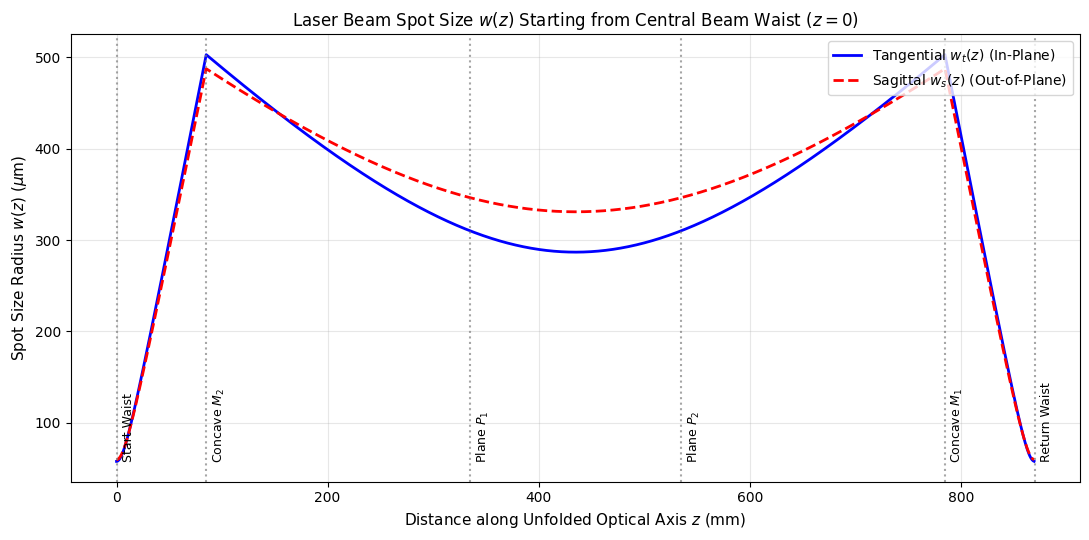

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

wavelength = 1064e-9
wavelength_mm = wavelength * 1e3

R = 150.0
theta_deg = 10.0
theta = np.radians(theta_deg)

d_top = 170.0
d_diag = 250.0
d_bot = 200.0

f_t = (R * np.cos(theta)) / 2.0
f_s = (R / np.cos(theta)) / 2.0

def M_space(d):
    return np.array([[1.0, d], [0.0, 1.0]])

def M_mirror(f):
    return np.array([[1.0, 0.0], [-1.0 / f, 1.0]])

def get_roundtrip_matrix(f):
    return (M_space(d_top / 2.0) @
            M_mirror(f) @
            M_space(d_diag) @
            M_space(d_bot) @
            M_space(d_diag) @
            M_mirror(f) @
            M_space(d_top / 2.0))

def solve_waist_q(m):
    a, b, c, d = m[0, 0], m[0, 1], m[1, 0], m[1, 1]
    m1 = (a + d) / 2.0
    print(m1)
    if abs(m1) > 1.0:
        print('Unstable cavity')
        return None
    inverse_q = -1j * np.sqrt(1.0 - m1**2) / np.abs(b)
    return 1.0 / inverse_q

def trace_spot_size(f_eff):
    M_rt = get_roundtrip_matrix(f_eff)
    q = solve_waist_q(M_rt)
    z_list = []
    w_list = []
    current_z = 0.0
    dz = 0.5
    path_sequence = [
        (d_top / 2.0, False),
        (0.0, True),
        (d_diag, False),
        (0.0, False),
        (d_bot, False),
        (0.0, False),
        (d_diag, False),
        (0.0, True),
        (d_top / 2.0, False)
    ]
    for dist, is_curved_mirror in path_sequence:
        if is_curved_mirror:
            q = 1.0 / (1.0 / q - 1.0 / f_eff)
        elif dist > 0:
            steps = int(np.ceil(dist / dz))
            step_d = dist / steps
            for _ in range(steps):
                z_list.append(current_z)
                inv_q = 1.0 / q
                w_mm = np.sqrt(wavelength_mm / (np.pi * np.abs(np.imag(inv_q))))
                w_list.append(w_mm * 1e3)
                q += step_d
                current_z += step_d
    return np.array(z_list), np.array(w_list)

z_t, w_t = trace_spot_size(f_t)
z_s, w_s = trace_spot_size(f_s)

plt.figure(figsize=(11, 5.5))
plt.plot(z_t, w_t, 'b-', label=r'Tangential $w_t(z)$ (In-Plane)', lw=2)
plt.plot(z_s, w_s, 'r--', label=r'Sagittal $w_s(z)$ (Out-of-Plane)', lw=2)

z_M2 = d_top / 2.0
z_P1 = z_M2 + d_diag
z_P2 = z_P1 + d_bot
z_M1 = z_P2 + d_diag
z_end = z_M1 + d_top / 2.0

components = [
    (0, "Start Waist"),
    (z_M2, r"Concave $M_2$"),
    (z_P1, r"Plane $P_1$"),
    (z_P2, r"Plane $P_2$"),
    (z_M1, r"Concave $M_1$"),
    (z_end, "Return Waist")
]

for pos, name in components:
    plt.axvline(pos, color='gray', linestyle=':', alpha=0.7)
    plt.text(pos + 5, min(w_t) * 1.05, name, rotation=90, fontsize=9, color='black')

plt.title(r'Laser Beam Spot Size $w(z)$ Starting from Central Beam Waist ($z = 0$)', fontsize=12)
plt.xlabel(r'Distance along Unfolded Optical Axis $z$ (mm)', fontsize=11)
plt.ylabel(r'Spot Size Radius $w(z)$ ($\mu$m)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()